<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Train stacked RBMs layer-by-layer (784-500-250)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.manifold import TSNE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

# Split into labeled (1,000) and unlabeled (remaining) for training
np.random.seed(42)
indices = np.random.permutation(len(x_train))
labeled_idx = indices[:1000]
unlabeled_idx = indices[1000:]

x_labeled, y_labeled = x_train[labeled_idx], y_train[labeled_idx]
x_unlabeled = x_train[unlabeled_idx]

# RBM Class Definition using NumPy
class RBM:
    def __init__(self, num_visible, num_hidden, lr=0.01):
        self.lr = lr
        self.weights = np.random.normal(0, 0.01, (num_visible, num_hidden))
        self.visible_bias = np.zeros(num_visible)
        self.hidden_bias = np.zeros(num_hidden)

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

    def sample_hidden(self, visible):
        prob_hidden = self.sigmoid(np.dot(visible, self.weights) + self.hidden_bias)
        return prob_hidden, (prob_hidden > np.random.rand(*prob_hidden.shape)).astype(np.float32)

    def sample_visible(self, hidden):
        prob_visible = self.sigmoid(np.dot(hidden, self.weights.T) + self.visible_bias)
        return prob_visible, (prob_visible > np.random.rand(*prob_visible.shape)).astype(np.float32)

    def train_step(self, data):
        # Contrastive Divergence (CD-1)
        pos_hid_prob, pos_hid_states = self.sample_hidden(data)
        pos_prods = np.dot(data.T, pos_hid_prob)
        pos_hid_act = np.sum(pos_hid_prob, axis=0)
        pos_vis_act = np.sum(data, axis=0)

        neg_vis_prob, neg_vis_states = self.sample_visible(pos_hid_states)
        neg_hid_prob, neg_hid_states = self.sample_hidden(neg_vis_states)
        neg_prods = np.dot(neg_vis_states.T, neg_hid_prob)
        neg_hid_act = np.sum(neg_hid_prob, axis=0)
        neg_vis_act = np.sum(neg_vis_states, axis=0)

        num_examples = data.shape[0]
        self.weights += self.lr * ((pos_prods - neg_prods) / num_examples)
        self.visible_bias += self.lr * ((pos_vis_act - neg_vis_act) / num_examples)
        self.hidden_bias += self.lr * ((pos_hid_act - neg_hid_act) / num_examples)

        error = np.mean((data - neg_vis_prob) ** 2)
        return error

    def train(self, data, epochs=10, batch_size=64):
        num_batches = data.shape[0] // batch_size
        for epoch in range(epochs):
            errors = []
            for i in range(num_batches):
                batch = data[i * batch_size : (i + 1) * batch_size]
                err = self.train_step(batch)
                errors.append(err)
            print(f"Epoch {epoch+1}/{epochs} - Loss: {np.mean(errors):.4f}")

# Train RBM 1 (784 -> 500)
print("Training RBM 1 (784 -> 500)...")
rbm1 = RBM(784, 500, lr=0.1)
rbm1.train(x_unlabeled, epochs=10, batch_size=128)

# Get hidden layer representation of unlabelled data
_, rbm1_hidden_features = rbm1.sample_hidden(x_unlabeled)

# Train RBM 2 (500 -> 250)
print("\nTraining RBM 2 (500 -> 250)...")
rbm2 = RBM(500, 250, lr=0.1)
rbm2.train(rbm1_hidden_features, epochs=10, batch_size=128)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training RBM 1 (784 -> 500)...
Epoch 1/10 - Loss: 0.0337
Epoch 2/10 - Loss: 0.0189
Epoch 3/10 - Loss: 0.0157
Epoch 4/10 - Loss: 0.0140
Epoch 5/10 - Loss: 0.0130
Epoch 6/10 - Loss: 0.0124
Epoch 7/10 - Loss: 0.0119
Epoch 8/10 - Loss: 0.0115
Epoch 9/10 - Loss: 0.0112
Epoch 10/10 - Loss: 0.0109

Training RBM 2 (500 -> 250)...
Epoch 1/10 - Loss: 0.1277
Epoch 2/10 - Loss: 0.1035
Epoch 3/10 - Loss: 0.0979
Epoch 4/10 - Loss: 0.0953
Epoch 5/10 - Loss: 0.0938
Epoch 6/10 - Loss: 0.0928
Epoch 7/10 - Loss: 0.0921
Epoch 8/10 - Loss: 0.0916
Epoch 9/10 - Loss: 0.0912
Epoch 10/10 - Loss: 0.0909


### Task 2: Visualize the learned weights of the first layer as image filters

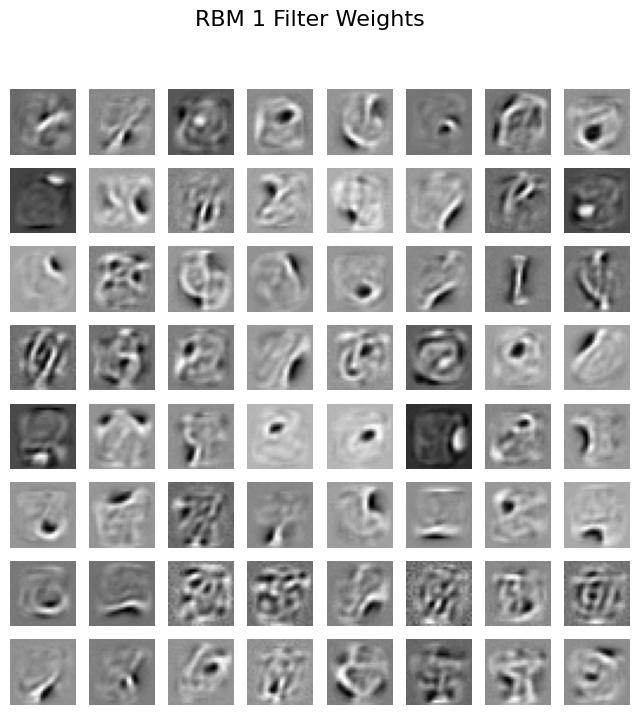

In [2]:
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    filter_weights = rbm1.weights[:, i].reshape(28, 28)
    ax.imshow(filter_weights, cmap='gray')
    ax.axis('off')
plt.suptitle("RBM 1 Filter Weights", fontsize=16)
plt.show()

### Task 3: Transfer weights into a Keras dense network and fine-tune with the labeled data

In [3]:
y_labeled_cat = to_categorical(y_labeled, 10)
y_test_cat = to_categorical(y_test, 10)

def build_fine_tune_model(pre_trained=True):
    model = Sequential([
        Input(shape=(784,)),
        Dense(500, activation='sigmoid', name='layer1'),
        Dense(250, activation='sigmoid', name='layer2'),
        Dense(10, activation='softmax', name='output')
    ])

    if pre_trained:
        # Transfer RBM 1 weights and biases
        model.get_layer('layer1').set_weights([rbm1.weights, rbm1.hidden_bias])
        # Transfer RBM 2 weights and biases
        model.get_layer('layer2').set_weights([rbm2.weights, rbm2.hidden_bias])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

dbn_model = build_fine_tune_model(pre_trained=True)
print("Fine-tuning DBN on 1,000 labels...")
history_dbn = dbn_model.fit(x_labeled, y_labeled_cat, validation_data=(x_test, y_test_cat), epochs=30, batch_size=32, verbose=0)
print(f"DBN final test accuracy: {history_dbn.history['val_accuracy'][-1]:.4f}")

Fine-tuning DBN on 1,000 labels...
DBN final test accuracy: 0.9224


### Task 4: Train the same network from random initialization for comparison

In [4]:
random_model = build_fine_tune_model(pre_trained=False)
print("Training model from random initialization on 1,000 labels...")
history_random = random_model.fit(x_labeled, y_labeled_cat, validation_data=(x_test, y_test_cat), epochs=30, batch_size=32, verbose=0)
print(f"Random Initialized model final test accuracy: {history_random.history['val_accuracy'][-1]:.4f}")

Training model from random initialization on 1,000 labels...
Random Initialized model final test accuracy: 0.8918


### Task 5: Compare accuracy and plot learned representations in 2-D using t-SNE

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


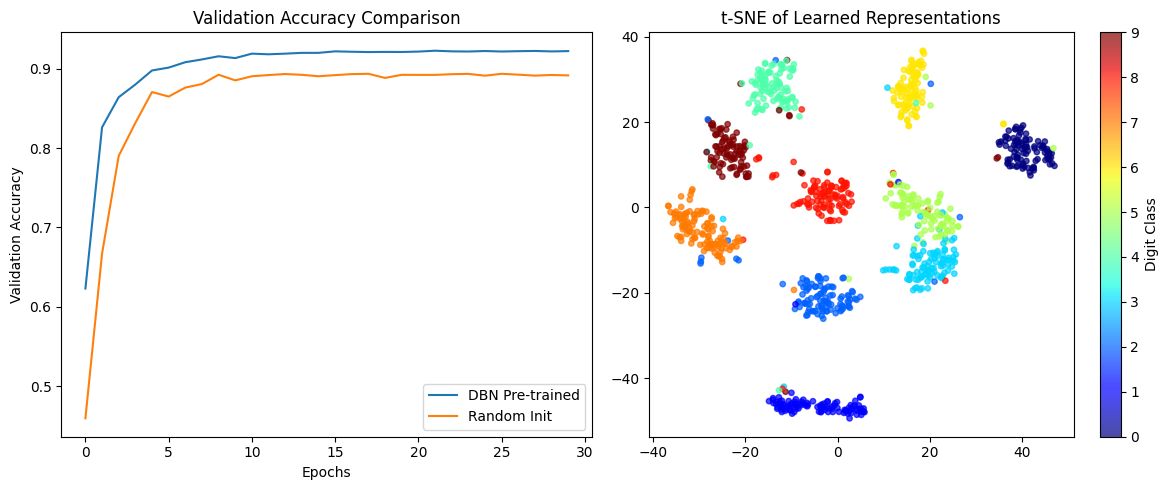

In [5]:
# Plot validation accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_dbn.history['val_accuracy'], label='DBN Pre-trained')
plt.plot(history_random.history['val_accuracy'], label='Random Init')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Comparison')
plt.legend()

# Extract intermediate representation
representation_model = Sequential(dbn_model.layers[:-1])
sub_indices = np.random.choice(len(x_test), 1000, replace=False)
x_test_sample = x_test[sub_indices]
y_test_sample = y_test[sub_indices]

learned_features = representation_model.predict(x_test_sample)

# Use t-SNE to map to 2-D
tsne = TSNE(n_components=2, random_state=42)
features_2d = tsne.fit_transform(learned_features)

# Plot 2D representation
plt.subplot(1, 2, 2)
scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1], c=y_test_sample, cmap='jet', alpha=0.7, s=15)
plt.colorbar(scatter, label='Digit Class')
plt.title('t-SNE of Learned Representations')
plt.tight_layout()
plt.show()